Shape: (62630, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62630 entries, 0 to 62629
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      62630 non-null  int64  
 1   UTC             62630 non-null  int64  
 2   Temperature[C]  62630 non-null  float64
 3   Humidity[%]     62630 non-null  float64
 4   TVOC[ppb]       62630 non-null  int64  
 5   eCO2[ppm]       62630 non-null  int64  
 6   Raw H2          62630 non-null  int64  
 7   Raw Ethanol     62630 non-null  int64  
 8   Pressure[hPa]   62630 non-null  float64
 9   PM1.0           62630 non-null  float64
 10  PM2.5           62630 non-null  float64
 11  NC0.5           62630 non-null  float64
 12  NC1.0           62630 non-null  float64
 13  NC2.5           62630 non-null  float64
 14  CNT             62630 non-null  int64  
 15  Fire Alarm      62630 non-null  int64  
dtypes: float64(8), int64(8)
memory usage: 7.6 MB
Unnamed: 0  

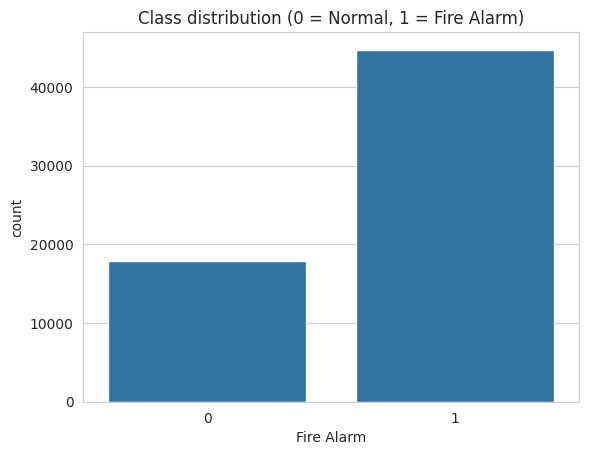

(50104, 12) (12526, 12)


In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style("whitegrid")
path = glob.glob("/kaggle/input/**/smoke_detection_iot.csv", recursive=True)[0]
df = pd.read_csv(path)
print("Shape:", df.shape)
df.head()

df.info()
print(df.isnull().sum())


before = len(df)
df = df.dropna().drop_duplicates()
print(f"Rows removed: {before - len(df)}")

print(df["Fire Alarm"].value_counts(normalize=True))
sns.countplot(x="Fire Alarm", data=df)
plt.title("Class distribution (0 = Normal, 1 = Fire Alarm)")
plt.show()

target = "Fire Alarm"
drop_cols = [c for c in ["Unnamed: 0", "UTC", "CNT"] if c in df.columns]

X = df.drop(columns=drop_cols + [target])
y = df[target]

# Train/Test split 80/20 مع الحفاظ على نسبة الفئات
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)







In [2]:
def evaluate(name, y_true, y_pred):
    res = {
        "Model": name,
        "Accuracy":  metrics.accuracy_score(y_true, y_pred),
        "Precision": metrics.precision_score(y_true, y_pred),
        "Recall":    metrics.recall_score(y_true, y_pred),
        "F1-Score":  metrics.f1_score(y_true, y_pred),
    }
    print(f"--- {name} ---")
    for k, v in res.items():
        if k != "Model":
            print(f"{k:10s}: {v:.4f}")
    return res

def plot_cm(y_true, y_pred, title):
    cm = metrics.confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Normal", "Fire"], yticklabels=["Normal", "Fire"])
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(title)
    plt.show()
    tn, fp, fn, tp = cm.ravel()
    print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

In [3]:
import time, pickle, os
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
])

# تدريب مع قياس الزمن
t0 = time.perf_counter()
lr_pipeline.fit(X_train, y_train)
lr_train_time = time.perf_counter() - t0

y_pred_lr_p = lr_pipeline.predict(X_test)
res_lr_p = evaluate("LR-Pipeline", y_test, y_pred_lr_p)

--- LR-Pipeline ---
Accuracy  : 0.9009
Precision : 0.9660
Recall    : 0.8927
F1-Score  : 0.9279


In [4]:
spw = (y_train == 0).sum() / (y_train == 1).sum()

xgb_pipeline = Pipeline([
    ("scaler", StandardScaler()),   # للتوحيد فقط، XGBoost لا يحتاجه
    ("clf", XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                          scale_pos_weight=spw, eval_metric="logloss",
                          random_state=42)),
])

t0 = time.perf_counter()
xgb_pipeline.fit(X_train, y_train)
xgb_train_time = time.perf_counter() - t0

y_pred_xgb_p = xgb_pipeline.predict(X_test)
res_xgb_p = evaluate("XGB-Pipeline", y_test, y_pred_xgb_p)

--- XGB-Pipeline ---
Accuracy  : 0.9999
Precision : 1.0000
Recall    : 0.9999
F1-Score  : 0.9999


In [5]:
os.makedirs("/kaggle/working/models", exist_ok=True)

def model_size_kb(pipe, name):
    path = f"/kaggle/working/models/{name}.pkl"
    with open(path, "wb") as f:
        pickle.dump(pipe, f)
    return os.path.getsize(path) / 1024

lr_size  = model_size_kb(lr_pipeline,  "lr_pipeline")
xgb_size = model_size_kb(xgb_pipeline, "xgb_pipeline")

size_table = pd.DataFrame({"Model": ["LR-Pipeline", "XGB-Pipeline"],
                           "Size (KB)": [round(lr_size, 2), round(xgb_size, 2)]})
display(size_table)

,Model,Size (KB)
0,LR-Pipeline,1.66
1,XGB-Pipeline,254.19


In [6]:
def time_inference(pipe, X, repeats=10):
    pipe.predict(X.iloc[:10])                      # warm-up
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        pipe.predict(X)
        times.append(time.perf_counter() - t0)
    total = float(np.median(times))                # الوسيط أكثر ثباتاً
    return total, total / len(X) * 1000            # (ثانية، ms للعينة)

lr_total,  lr_single  = time_inference(lr_pipeline,  X_test)
xgb_total, xgb_single = time_inference(xgb_pipeline, X_test)

time_table = pd.DataFrame({
    "Model": ["LR-Pipeline", "XGB-Pipeline"],
    "Total Test Inference Time (s)": [round(lr_total, 4), round(xgb_total, 4)],
    "Single Inference Time (ms)": [round(lr_single, 5), round(xgb_single, 5)],
})
display(time_table)

,Model,Total Test Inference Time (s),Single Inference Time (ms)
0,LR-Pipeline,0.0025,0.0002
1,XGB-Pipeline,0.0213,0.0017


In [7]:
summary = pd.DataFrame({
    "Model": ["LR-Pipeline", "XGB-Pipeline"],
    "Accuracy": [res_lr_p["Accuracy"], res_xgb_p["Accuracy"]],
    "F1": [res_lr_p["F1-Score"], res_xgb_p["F1-Score"]],
    "Recall": [res_lr_p["Recall"], res_xgb_p["Recall"]],
    "Train time (s)": [lr_train_time, xgb_train_time],
    "Size (KB)": [lr_size, xgb_size],
    "Single inference (ms)": [lr_single, xgb_single],
}).round(4)
display(summary)

,Model,Accuracy,F1,Recall,Train time (s),Size (KB),Single inference (ms)
0,LR-Pipeline,0.9009,0.9279,0.8927,0.6848,1.6592,0.0002
1,XGB-Pipeline,0.9999,0.9999,0.9999,0.5785,254.1924,0.0017
